# V/MA case study

Pairs trading takes two stocks that should move together and bets that they will come back together after they drift apart. Here the two stocks are Visa (V) and Mastercard (MA), which run similar payment networks.

The idea is simple. I fit a line between the two log prices over a two-year formation window. The gap from that line is the spread. When the spread gets unusually wide, I buy the cheap stock and short the expensive one. I close the trade when the gap goes back to normal.

This notebook looks at one pair only. It uses the same windows and rules as the full study in `pairs.py` and `config.py`. All the numbers in the text below are printed by the code cells.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, os.getcwd())
import config
import pairs

os.makedirs("Images", exist_ok=True)
os.makedirs("results", exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

prices = pd.read_csv(config.PRICES_PATH, index_col=0, parse_dates=True)
Y_NAME, X_NAME = "V", "MA"
py = prices[Y_NAME].to_numpy()
px = prices[X_NAME].to_numpy()
dates = prices.index
windows = pairs.make_windows(len(prices))
print(f"Pair: {Y_NAME} (Y) and {X_NAME} (X)")
print(f"Sample: {dates[0].date()} to {dates[-1].date()}, {len(prices)} trading days, {len(windows)} windows")

Pair: V (Y) and MA (X)
Sample: 2015-01-02 to 2026-10-30, 2975 trading days, 19 windows


## Prices and the log price ratio

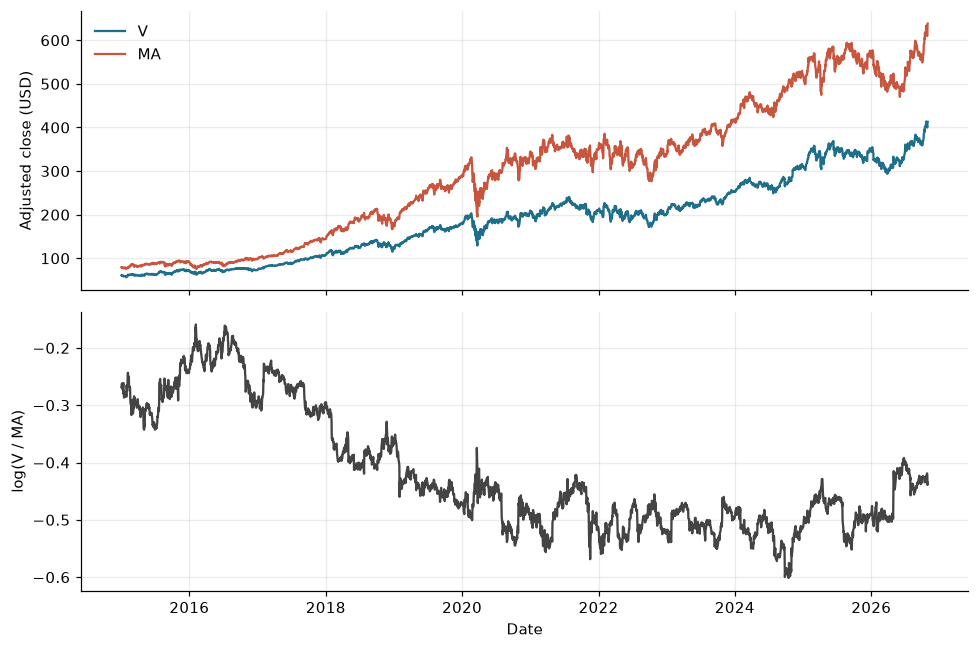

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(dates, py, label=Y_NAME, color="#1f6f8b")
axes[0].plot(dates, px, label=X_NAME, color="#c8553d")
axes[0].set_ylabel("Adjusted close (USD)")
axes[0].legend(frameon=False)
axes[1].plot(dates, np.log(py / px), color="#444444")
axes[1].set_ylabel("log(V / MA)")
axes[1].set_xlabel("Date")
fig.tight_layout()
plt.show()

The two prices rise together over most of the sample. The log ratio wanders rather than sitting still, which is why a test is needed before assuming the gap always closes.

## Correlation versus cointegration (window 0)

In [3]:
w0 = windows[0]
fs = slice(w0.form_start, w0.form_end)
ret_y = pd.Series(py[fs]).pct_change().dropna()
ret_x = pd.Series(px[fs]).pct_change().dropna()
fit0 = pairs.fit_window(py, px, w0)
print(f"Window 0 formation period: {dates[w0.form_start].date()} to {dates[w0.form_end - 1].date()}")
print(f"Correlation of daily returns: {ret_y.corr(ret_x):.4f}")
print(f"Engle-Granger p-value on log prices: {fit0.pvalue:.4f}")

Window 0 formation period: 2015-01-02 to 2016-12-30
Correlation of daily returns: 0.8487
Engle-Granger p-value on log prices: 0.6615


Correlation and cointegration answer different questions. Correlation of daily returns asks whether the two stocks move up and down on the same days. Cointegration asks whether the gap between their log prices keeps returning to a fixed level over time.

Two stocks can have highly correlated daily returns and still drift apart for years, because small daily differences add up. In window 0 the daily return correlation is high, yet the Engle-Granger p-value is far above 0.05, so the test does not reject the idea that the spread is a random walk.

## Window 0 in detail

In [4]:
res0 = pairs.evaluate_pair_window(py, px, w0)
fit = res0.fit
print(pd.Series({"alpha": fit.alpha, "beta": fit.beta, "sigma": fit.sigma,
                 "eg_pvalue": fit.pvalue, "half_life_days": fit.half_life}).to_string(float_format=lambda v: f"{v:.4f}"))

alpha            -0.3855
beta              1.0300
sigma             0.0456
eg_pvalue         0.6615
half_life_days   54.3399


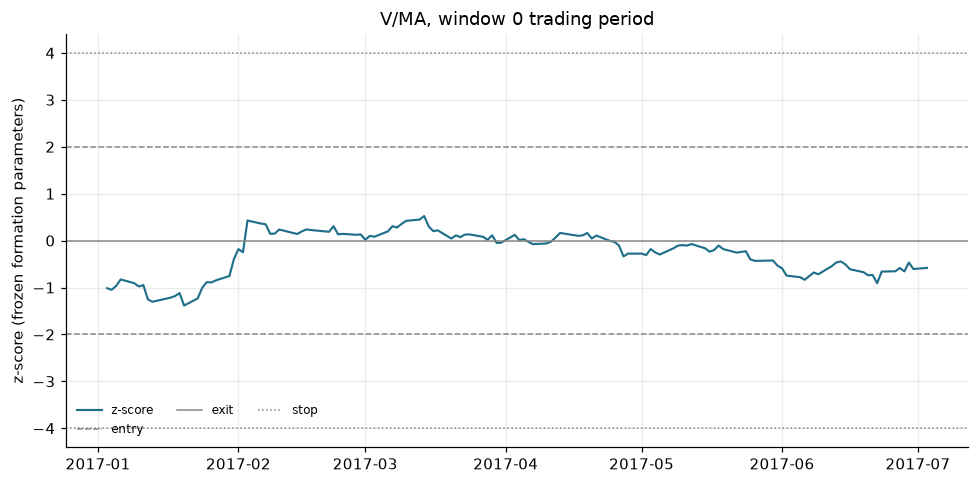

z-score range in the window 0 trading period: min -1.38, max 0.52
Completed trades in window 0: 0


In [5]:
trade_dates = dates[w0.trade_start:w0.trade_end]
z = res0.z
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(trade_dates, z, color="#1f6f8b", lw=1.4, label="z-score")
for level, style, name in [(config.ENTRY_Z, "--", "entry"), (-config.ENTRY_Z, "--", None),
                           (config.EXIT_Z, "-", "exit"),
                           (config.STOP_Z, ":", "stop"), (-config.STOP_Z, ":", None)]:
    ax.axhline(level, color="#888888", ls=style, lw=1, label=name)
for i, tr in enumerate(res0.result.trades):
    ax.scatter(trade_dates[tr.entry_idx], z[tr.entry_idx], marker="^", s=70, color="#2a9d4a", zorder=5,
               label="entry" if i == 0 else None)
    ax.scatter(trade_dates[tr.exit_idx], z[tr.exit_idx], marker="v", s=70, color="#c8553d", zorder=5,
               label="exit" if i == 0 else None)
ax.set_ylabel("z-score (frozen formation parameters)")
ax.set_title("V/MA, window 0 trading period")
ax.legend(frameon=False, ncol=3, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig("Images/vma_zscore_window0.png", bbox_inches="tight")
plt.show()
print(f"z-score range in the window 0 trading period: min {np.nanmin(z):.2f}, max {np.nanmax(z):.2f}")
print("Completed trades in window 0:", len(res0.result.trades))
for tr in res0.result.trades:
    print(f"  direction {tr.direction:+d}, entry {trade_dates[tr.entry_idx].date()} (z={tr.entry_z:.2f}), "
          f"exit {trade_dates[tr.exit_idx].date()} (z={tr.exit_z:.2f}), reason {tr.reason}")

In window 0 the frozen z-score never gets near the entry lines, so the strategy takes no trade and there are no entries or exits to mark. This is the rule working as written, not a gap in the plot. The p-value in the fit above is above 0.05, so V/MA would also be ineligible under COINT in this window.

## One row per window

In [6]:
rows = []
results = []
for w in windows:
    r = pairs.evaluate_pair_window(py, px, w)
    results.append(r)
    f = r.fit
    elig = pairs.eligible_coint(f.beta, f.pvalue, f.half_life)
    net_window = float(np.prod(1.0 + r.result.net) - 1.0)
    reasons = ", ".join(tr.reason for tr in r.result.trades) if r.result.trades else "none"
    rows.append({
        "window": w.k,
        "trading_start": dates[w.trade_start].date(),
        "eg_pvalue": f.pvalue,
        "half_life": f.half_life,
        "beta": f.beta,
        "eligible_COINT": "yes" if elig else "no",
        "completed_trades": len(r.result.trades),
        "net_return": net_window,
        "exit_reasons": reasons,
    })
table = pd.DataFrame(rows)
table.to_csv("results/vma_case_study_windows.csv", index=False)
print(f"Windows eligible under COINT: {(table.eligible_COINT == 'yes').sum()} of {len(table)}")
print(f"Windows with at least one completed trade: {(table.completed_trades > 0).sum()}")
print(f"Total completed trades: {table.completed_trades.sum()}")
display(table.style.format({"eg_pvalue": "{:.4f}", "half_life": "{:.2f}", "beta": "{:.4f}", "net_return": "{:.4%}"}).hide(axis="index"))

Windows eligible under COINT: 7 of 19
Windows with at least one completed trade: 11
Total completed trades: 15


window,trading_start,eg_pvalue,half_life,beta,eligible_COINT,completed_trades,net_return,exit_reasons
0,2017-01-03,0.6615,54.34,1.0300,no,0,0.0000%,none
1,2017-07-05,0.0410,22.25,0.8465,yes,0,0.0000%,none
2,2018-01-03,0.1182,21.32,0.7961,no,1,-0.0532%,window_end
3,2018-07-05,0.2673,26.75,0.7539,no,0,0.0000%,none
4,2019-01-04,0.0303,12.91,0.7641,yes,1,3.4063%,revert
5,2019-07-08,0.0642,11.34,0.7543,no,1,2.0597%,revert
6,2020-01-06,0.0135,9.12,0.8033,yes,1,0.4515%,window_end
7,2020-07-07,0.0114,4.51,0.8077,yes,2,3.1167%,"revert, revert"
8,2021-01-05,0.0158,6.92,0.8009,yes,2,2.2928%,"revert, window_end"
9,2021-07-07,0.6417,10.67,0.7917,no,2,7.2800%,"revert, revert"


The table shows how much the formation p-value changes from window to window. V/MA passes the raw 0.05 rule only in some windows. The windows that are ineligible under COINT still trade under the ALL rule, and some of them have positive net returns while some of the eligible ones do not. I did not look for a pattern beyond reading the table. With 19 windows and one pair, any pattern here is an observation, not evidence.

## Equity curves: every window versus COINT-eligible windows only

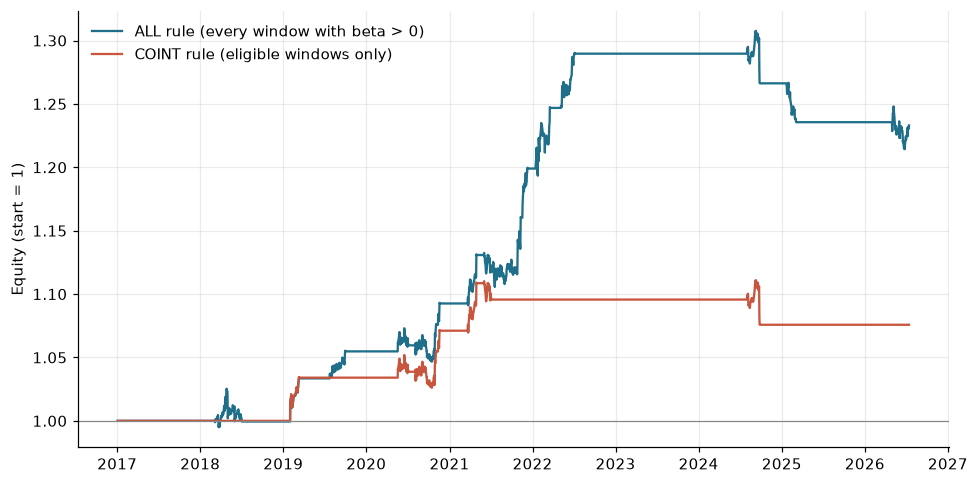

                                  ALL    COINT
net annualized return          0.0223   0.0077
net Sharpe                     0.7368   0.4377
max drawdown                  -0.0714  -0.0317
days with nonzero net return 628.0000 226.0000


In [7]:
net_all = np.concatenate([r.result.net for r in results])
net_coint = np.concatenate([
    r.result.net if pairs.eligible_coint(r.fit.beta, r.fit.pvalue, r.fit.half_life) else np.zeros(len(r.result.net))
    for r in results
])
curve_dates = dates[windows[0].trade_start:windows[-1].trade_end]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve_dates, pairs.equity_curve(net_all), color="#1f6f8b", label="ALL rule (every window with beta > 0)")
ax.plot(curve_dates, pairs.equity_curve(net_coint), color="#c8553d", label="COINT rule (eligible windows only)")
ax.axhline(1.0, color="#888888", lw=0.8)
ax.set_ylabel("Equity (start = 1)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
summary = pd.DataFrame({
    "ALL": [pairs.annualized_return(net_all), pairs.sharpe(net_all), pairs.max_drawdown(net_all), int((net_all != 0).sum())],
    "COINT": [pairs.annualized_return(net_coint), pairs.sharpe(net_coint), pairs.max_drawdown(net_coint), int((net_coint != 0).sum())],
}, index=["net annualized return", "net Sharpe", "max drawdown", "days with nonzero net return"]).astype(float)
print(summary.to_string(float_format=lambda v: f"{v:.4f}"))

The two curves differ because the COINT curve sits flat in every window the rule skips. The Sharpe ratios are computed with no risk-free subtraction. The COINT curve has far fewer days with a nonzero return, so its Sharpe rests on much less data.

## Cost reconciliation

In [8]:
gross_all = np.concatenate([r.result.gross for r in results])
cost_all = np.concatenate([r.result.trade_cost for r in results])
net_of_trade_cost = gross_all - cost_all

bps = config.COST_BPS / 10000
changes = 0.0
for r in results:
    pos = r.result.position
    changes += np.abs(np.diff(np.concatenate([[0], pos]))).sum() + abs(pos[-1])
cost_from_changes = changes * bps
cost_from_trades = 2 * sum(len(r.result.trades) for r in results) * bps
cost_from_gap = float(np.sum(gross_all) - np.sum(net_of_trade_cost))
cost_from_compounded = float((np.prod(1 + gross_all) - 1) - (np.prod(1 + net_of_trade_cost) - 1))

print(f"Total trade cost, sum(abs(position changes)) * bps:         {cost_from_changes:.6f}")
print(f"Total trade cost, 2 * completed trades * bps:               {cost_from_trades:.6f}")
print(f"Gap in cumulative simple returns (gross minus net of cost): {cost_from_gap:.6f}")
print(f"Gap in compounded returns (for reference):                  {cost_from_compounded:.6f}")
rel = abs(cost_from_changes - cost_from_gap) / cost_from_changes if cost_from_changes else 0.0
print(f"Relative difference, changes versus simple-return gap: {rel:.2e}")
assert rel <= 0.05, "cost reconciliation failed"

Total trade cost, sum(abs(position changes)) * bps:         0.015000


Total trade cost, 2 * completed trades * bps:               0.015000
Gap in cumulative simple returns (gross minus net of cost): 0.015000
Gap in compounded returns (for reference):                  0.018718
Relative difference, changes versus simple-return gap: 9.25e-16


The three ways of measuring total trade cost agree. The count of position changes, twice the number of completed trades, and the gap between gross and net-of-trade-cost simple returns all give the same figure, and the relative difference is at the level of floating-point error. The compounded gap is a little larger because returns compound, which is why the check uses simple returns. The check passes.

## What this shows and what it does not

**What this shows.** The pipeline runs end to end on real prices for one pair. The windows, the frozen parameters, the signal lag, and the cost accounting behave as intended, and the cost check reconciles.

**What it does not show.** One pair is a case study, not evidence. It has 19 windows and a small number of trades, so no result here says whether cointegration predicts profit. Any story I could tell about why a particular window did well or badly would be a post hoc explanation. The full 30-pair walk-forward in the second notebook is where the research question gets tested.